In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from pathlib import Path

In [4]:
PROJECT_DIR = Path.cwd().parent

CLEAN_DIR = PROJECT_DIR / "cleaned_data"

In [5]:
customers_clean = pd.read_csv(CLEAN_DIR / "customers_clean.csv")

orders_clean = pd.read_csv(CLEAN_DIR / "orders_clean.csv")

order_items_clean = pd.read_csv(CLEAN_DIR / "order_items_clean.csv")

payments_clean = pd.read_csv(CLEAN_DIR / "payments_clean.csv")

reviews_clean = pd.read_csv(CLEAN_DIR / "reviews_clean.csv")

products_clean = pd.read_csv(CLEAN_DIR / "products_clean.csv")

sellers_clean = pd.read_csv(CLEAN_DIR / "sellers_clean.csv")

category_translation_clean = pd.read_csv(CLEAN_DIR / "category_translation_clean.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [6]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(orders_clean[col])

In [8]:
payments_by_order = payments_clean.groupby("order_id", as_index=False)["payment_value"].sum()

orders_analysis = pd.merge(
    orders_clean,
    payments_by_order,
    on="order_id",
    how="left"
)

orders_analysis.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,28.62


In [9]:
orders_clean["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

### Visualize order statuses

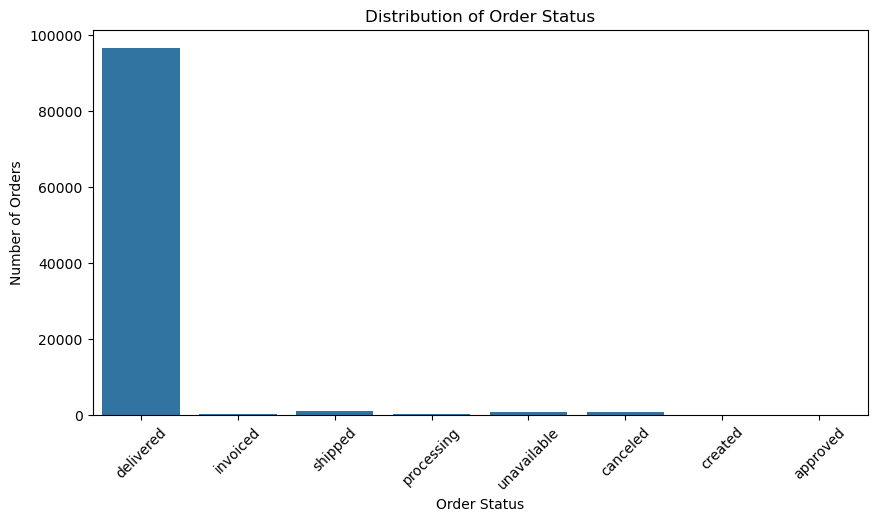

In [10]:
plt.figure(figsize=(10, 5))

sns.countplot(data=orders_clean, x="order_status")

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

### Monthly Revenue Analysis

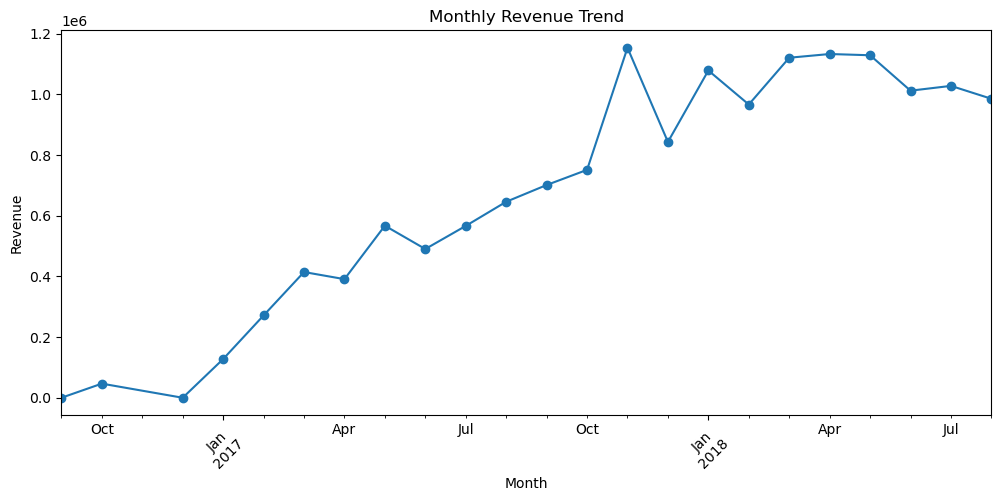

In [11]:
delivered_orders = orders_analysis[
    orders_analysis["order_status"] == "delivered"
].copy()

delivered_orders["month"] = delivered_orders["order_purchase_timestamp"].dt.to_period("M")

monthly_revenue = delivered_orders.groupby("month")["payment_value"].sum()

monthly_revenue.plot(figsize=(12, 5), marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

## Product and Customer Analysis

### Top 10 product categories

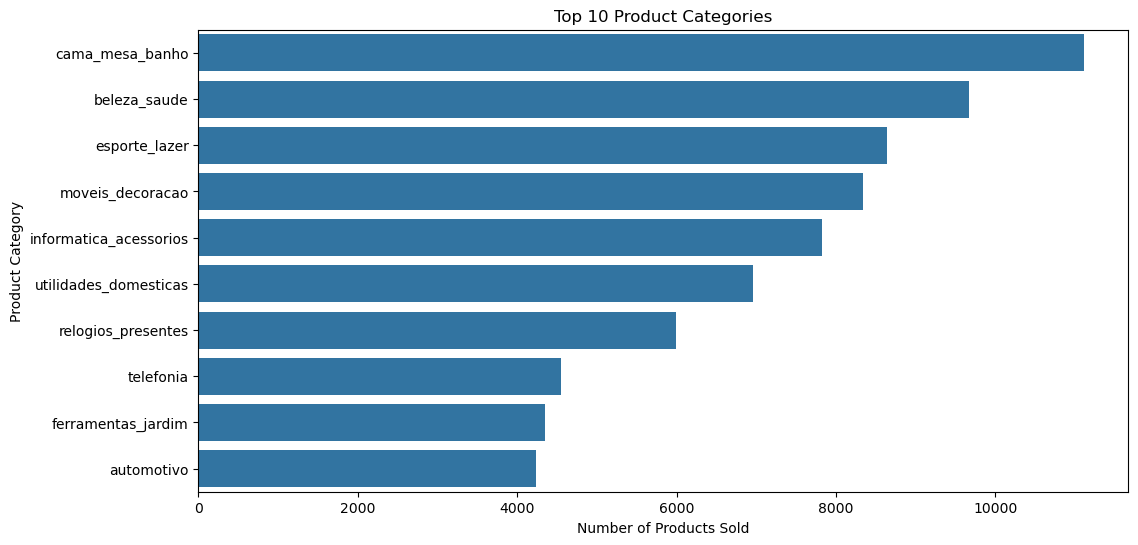

In [12]:
top_categories = order_items_clean.merge(
    products_clean,
    on="product_id"
)

top_categories = top_categories["product_category_name"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_categories.values, y=top_categories.index)

plt.title("Top 10 Product Categories")
plt.xlabel("Number of Products Sold")
plt.ylabel("Product Category")

plt.show()

### Top 10 customer cities

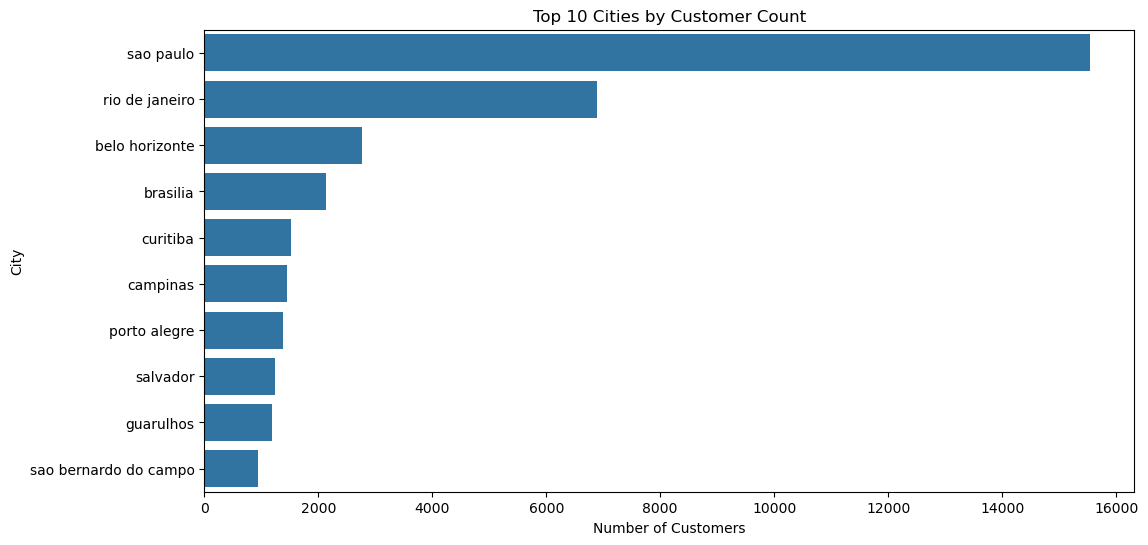

In [13]:
top_cities = customers_clean["customer_city"].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_cities.values, y=top_cities.index)

plt.title("Top 10 Cities by Customer Count")
plt.xlabel("Number of Customers")
plt.ylabel("City")

plt.show()

### Payment method analysis

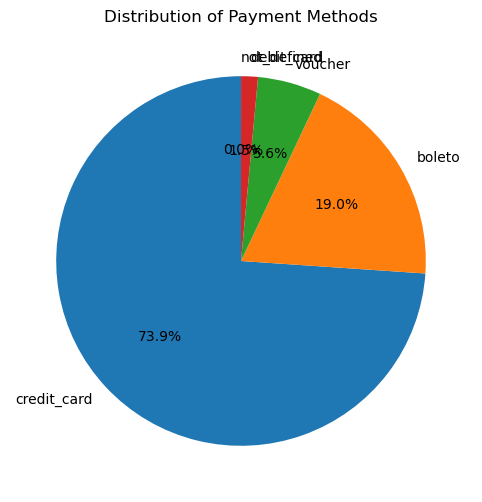

In [14]:
payment_methods = payments_clean["payment_type"].value_counts()

plt.figure(figsize=(8, 6))

plt.pie(
    payment_methods.values,
    labels=payment_methods.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Payment Methods")

plt.show()

### Average review score

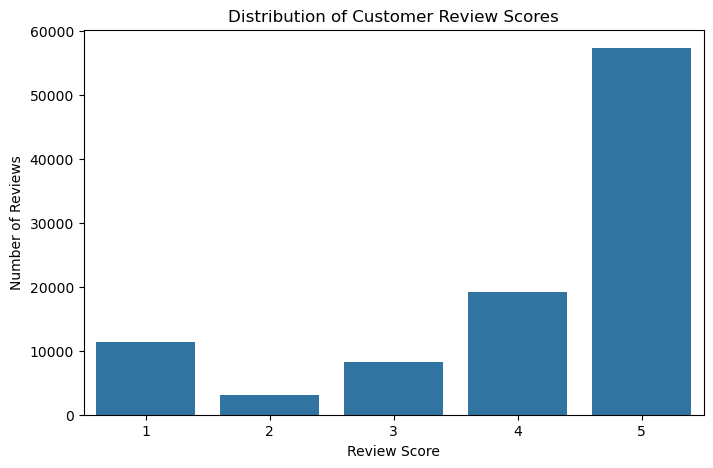

In [15]:
plt.figure(figsize=(8, 5))

sns.countplot(data=reviews_clean, x="review_score")

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.show()

## Delivery Performance Analysis

### Calculate delivery time

In [16]:
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_purchase_timestamp"]
).dt.days

delivered_orders[["order_id", "delivery_days"]].head()

,order_id,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,8.0
1,53cdb2fc8bc7dce0b6741e2150273451,13.0
2,47770eb9100c2d0c44946d9cf07ec65d,9.0
3,949d5b44dbf5de918fe9c16f97b45f8a,13.0
4,ad21c59c0840e6cb83a9ceb5573f8159,2.0


### Average delivery time

In [17]:
print("Average Delivery Days:", delivered_orders["delivery_days"].mean())

print("Minimum Delivery Days:", delivered_orders["delivery_days"].min())

print("Maximum Delivery Days:", delivered_orders["delivery_days"].max())

Average Delivery Days: 12.093604229294082
Minimum Delivery Days: 0.0
Maximum Delivery Days: 209.0


### Delivery time distribution

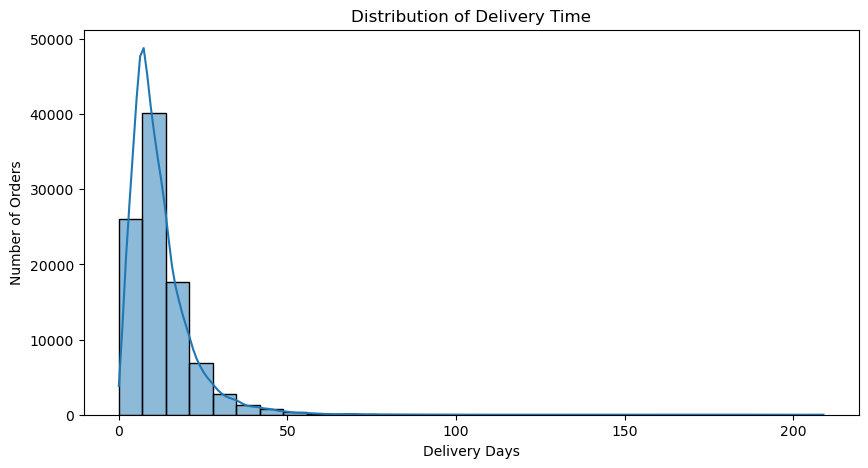

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(delivered_orders["delivery_days"], bins=30, kde=True)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")

plt.show()

### Late delivery analysis

In [19]:
delivered_orders["late_delivery"] = (
    delivered_orders["order_delivered_customer_date"] >
    delivered_orders["order_estimated_delivery_date"]
)

print(delivered_orders["late_delivery"].value_counts())

late_delivery
False    88652
True      7826
Name: count, dtype: int64


### Visualize late deliveries

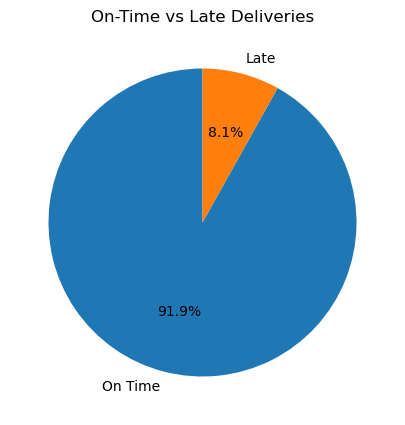

In [20]:
late_counts = delivered_orders["late_delivery"].value_counts()

plt.figure(figsize=(7, 5))

plt.pie(
    late_counts,
    labels=["On Time", "Late"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("On-Time vs Late Deliveries")

plt.show()

## Customer Purchase Behaviour

### Create customer purchase dataset

In [21]:
customer_data = delivered_orders.groupby("customer_id").agg(
    total_orders=("order_id", "nunique"),
    total_spending=("payment_value", "sum"),
    last_purchase=("order_purchase_timestamp", "max")
).reset_index()

customer_data.head()

,customer_id,total_orders,total_spending,last_purchase
0,00012a2ce6f8dcda20d059ce98491703,1,114.74,2017-11-14 16:08:26
1,000161a058600d5901f007fab4c27140,1,67.41,2017-07-16 09:40:32
2,0001fd6190edaaf884bcaf3d49edf079,1,195.42,2017-02-28 11:06:43
3,0002414f95344307404f0ace7a26f1d5,1,179.35,2017-08-16 13:09:20
4,000379cdec625522490c315e70c7a9fb,1,107.01,2018-04-02 13:42:17


### Calculate Recency

In [22]:
reference_date = delivered_orders["order_purchase_timestamp"].max()

customer_data["recency"] = (
    reference_date - customer_data["last_purchase"]
).dt.days

customer_data.head()

,customer_id,total_orders,total_spending,last_purchase,recency
0,00012a2ce6f8dcda20d059ce98491703,1,114.74,2017-11-14 16:08:26,287
1,000161a058600d5901f007fab4c27140,1,67.41,2017-07-16 09:40:32,409
2,0001fd6190edaaf884bcaf3d49edf079,1,195.42,2017-02-28 11:06:43,547
3,0002414f95344307404f0ace7a26f1d5,1,179.35,2017-08-16 13:09:20,378
4,000379cdec625522490c315e70c7a9fb,1,107.01,2018-04-02 13:42:17,149


### Customer summary

In [24]:
customer_data[["total_orders", "total_spending", "recency"]].describe()

,total_orders,total_spending,recency
count,96478.0,96478.000000,96478.000000
mean,1.0,159.854700,239.121364
std,0.0,218.812616,152.836972
min,1.0,0.000000,0.000000
25%,1.0,61.880000,115.000000
50%,1.0,105.280000,220.000000
75%,1.0,176.330000,349.000000
max,1.0,13664.080000,713.000000


### Customer spending distribution

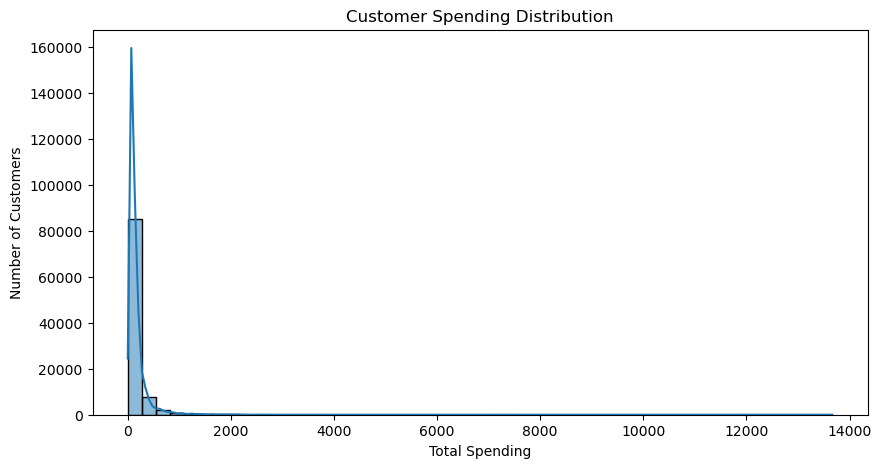

In [25]:
plt.figure(figsize=(10, 5))

sns.histplot(customer_data["total_spending"], bins=50, kde=True)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")

plt.show()

### Purchase frequency distribution

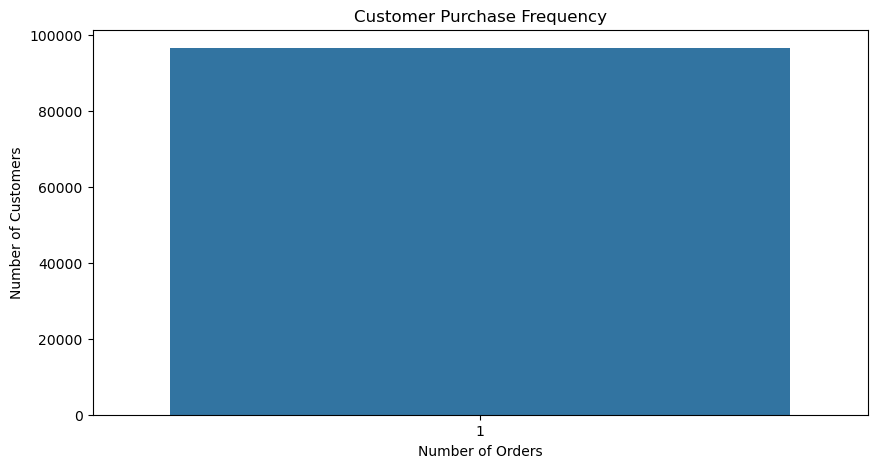

In [26]:
plt.figure(figsize=(10, 5))

sns.countplot(data=customer_data, x="total_orders")

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.show()

### Recency distribution

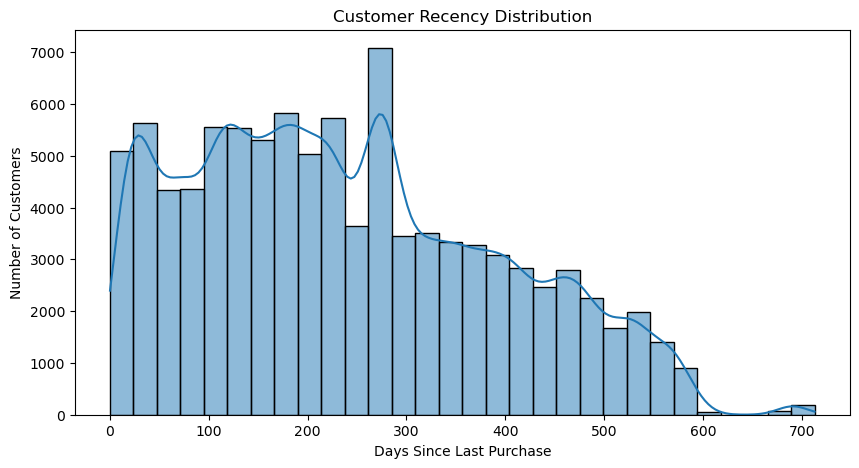

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(customer_data["recency"], bins=30, kde=True)

plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.show()

## RFM Customer Segmentation

### Step 1 – Create RFM metrics

In [28]:
rfm = delivered_orders.groupby("customer_id").agg(
    Recency=("order_purchase_timestamp", lambda x: (reference_date - x.max()).days),
    Frequency=("order_id", "nunique"),
    Monetary=("payment_value", "sum")
).reset_index()

rfm.head()

,customer_id,Recency,Frequency,Monetary
0,00012a2ce6f8dcda20d059ce98491703,287,1,114.74
1,000161a058600d5901f007fab4c27140,409,1,67.41
2,0001fd6190edaaf884bcaf3d49edf079,547,1,195.42
3,0002414f95344307404f0ace7a26f1d5,378,1,179.35
4,000379cdec625522490c315e70c7a9fb,149,1,107.01


### Step 2 – Check RFM summary

In [29]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,96478.000000,96478.0,96478.000000
mean,239.121364,1.0,159.854700
std,152.836972,0.0,218.812616
min,0.000000,1.0,0.000000
25%,115.000000,1.0,61.880000
50%,220.000000,1.0,105.280000
75%,349.000000,1.0,176.330000
max,713.000000,1.0,13664.080000


### Step 3 – Check the dataset shape

In [30]:
print("RFM Dataset Shape:", rfm.shape)
print("Unique Customers:", rfm["customer_id"].nunique())

RFM Dataset Shape: (96478, 4)
Unique Customers: 96478


### RFM Distribution

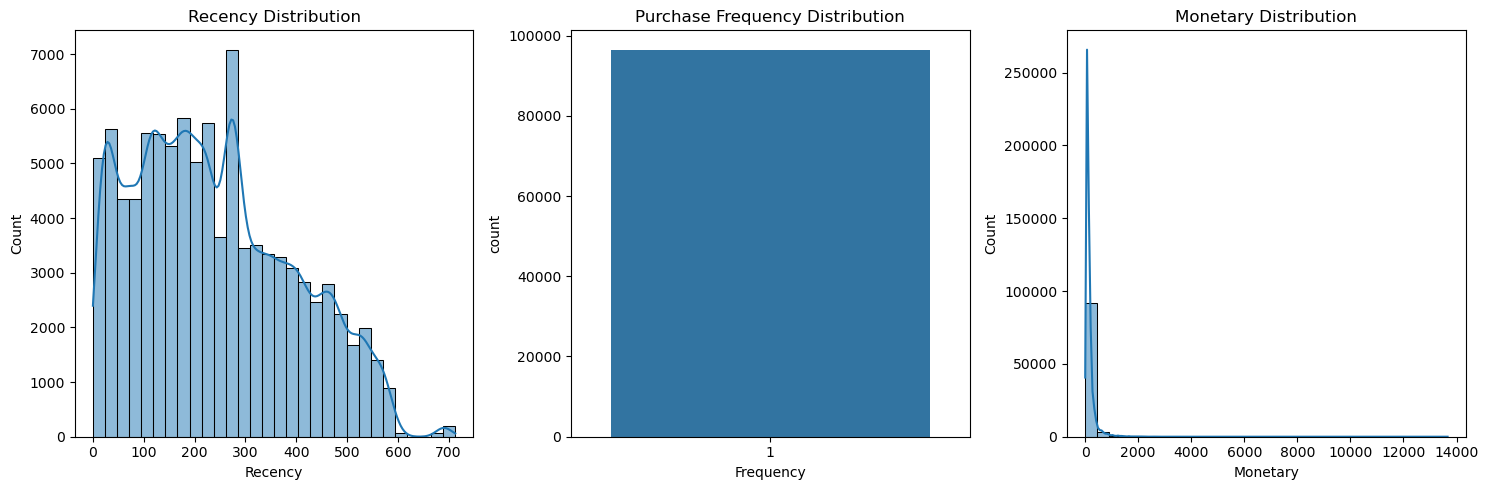

In [31]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(rfm["Recency"], bins=30, kde=True)
plt.title("Recency Distribution")

plt.subplot(1, 3, 2)
sns.countplot(data=rfm, x="Frequency")
plt.title("Purchase Frequency Distribution")

plt.subplot(1, 3, 3)
sns.histplot(rfm["Monetary"], bins=30, kde=True)
plt.title("Monetary Distribution")

plt.tight_layout()
plt.show()

### RFM Correlation Analysis

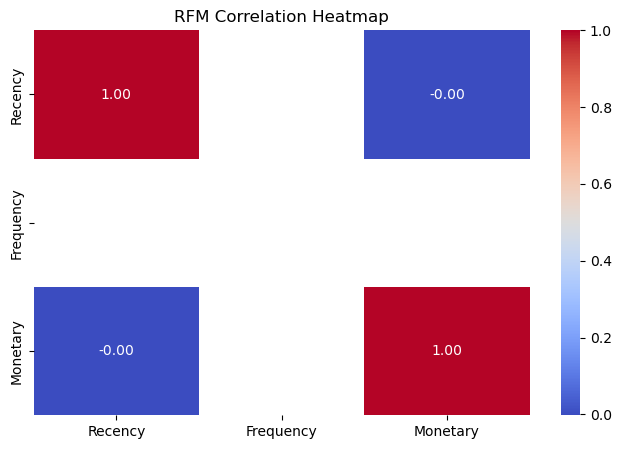

In [32]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    rfm[["Recency", "Frequency", "Monetary"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("RFM Correlation Heatmap")
plt.show()

### RFM Segmentation Preparation

In [33]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

rfm.head()

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,00012a2ce6f8dcda20d059ce98491703,287,1,114.74,2,1,3
1,000161a058600d5901f007fab4c27140,409,1,67.41,1,1,2
2,0001fd6190edaaf884bcaf3d49edf079,547,1,195.42,1,1,4
3,0002414f95344307404f0ace7a26f1d5,378,1,179.35,1,1,4
4,000379cdec625522490c315e70c7a9fb,149,1,107.01,3,1,3


### Calculate RFM Score

In [34]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm["RFM_Score"] = rfm["RFM_Score"].astype(int)

rfm.head()

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,00012a2ce6f8dcda20d059ce98491703,287,1,114.74,2,1,3,213
1,000161a058600d5901f007fab4c27140,409,1,67.41,1,1,2,112
2,0001fd6190edaaf884bcaf3d49edf079,547,1,195.42,1,1,4,114
3,0002414f95344307404f0ace7a26f1d5,378,1,179.35,1,1,4,114
4,000379cdec625522490c315e70c7a9fb,149,1,107.01,3,1,3,313


### Customer Segmentation

In [35]:
def segment_customer(row):
    if row["RFM_Score"] >= 444:
        return "Best Customers"
    elif row["RFM_Score"] >= 344:
        return "Loyal Customers"
    elif row["RFM_Score"] >= 244:
        return "Potential Loyalists"
    elif row["RFM_Score"] >= 144:
        return "At Risk"
    else:
        return "Lost Customers"

rfm["Customer_Segment"] = rfm.apply(segment_customer, axis=1)

rfm.head()

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,00012a2ce6f8dcda20d059ce98491703,287,1,114.74,2,1,3,213,At Risk
1,000161a058600d5901f007fab4c27140,409,1,67.41,1,1,2,112,Lost Customers
2,0001fd6190edaaf884bcaf3d49edf079,547,1,195.42,1,1,4,114,Lost Customers
3,0002414f95344307404f0ace7a26f1d5,378,1,179.35,1,1,4,114,Lost Customers
4,000379cdec625522490c315e70c7a9fb,149,1,107.01,3,1,3,313,Potential Loyalists


### Check Customer Frequency

In [36]:
print("Frequency Distribution:")
print(rfm["Frequency"].value_counts().sort_index())

print("\nUnique Frequency Values:")
print(rfm["Frequency"].nunique())

print("\nMinimum Frequency:", rfm["Frequency"].min())
print("Maximum Frequency:", rfm["Frequency"].max())

Frequency Distribution:
Frequency
1    96478
Name: count, dtype: int64

Unique Frequency Values:
1

Minimum Frequency: 1
Maximum Frequency: 1


### Customer Repeat Purchase Analysis

In [38]:
delivered_orders = pd.merge(
    delivered_orders,
    customers_clean[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

delivered_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_value,month,delivery_days,late_delivery,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,38.71,2017-10,8.0,False,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,141.46,2018-07,13.0,False,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,179.12,2018-08,9.0,False,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,72.20,2017-11,13.0,False,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,28.62,2018-02,2.0,False,72632f0f9dd73dfee390c9b22eb56dd6


In [39]:
customer_orders = delivered_orders.groupby(
    "customer_unique_id"
)["order_id"].nunique()

repeat_customers = customer_orders[customer_orders > 1]

one_time_customers = customer_orders[customer_orders == 1]

print("Total Unique Customers:", len(customer_orders))
print("One-Time Customers:", len(one_time_customers))
print("Repeat Customers:", len(repeat_customers))

print("Repeat Purchase Rate:",
      round((len(repeat_customers) / len(customer_orders)) * 100, 2), "%")

Total Unique Customers: 93358
One-Time Customers: 90557
Repeat Customers: 2801
Repeat Purchase Rate: 3.0 %


### Repeat Purchase Distribution

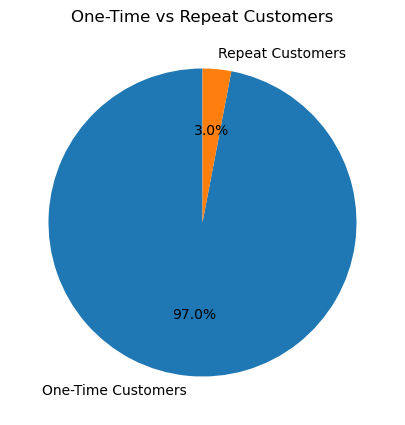

In [40]:
repeat_counts = pd.Series({
    "One-Time Customers": len(one_time_customers),
    "Repeat Customers": len(repeat_customers)
})

plt.figure(figsize=(7, 5))

plt.pie(
    repeat_counts,
    labels=repeat_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("One-Time vs Repeat Customers")

plt.show()

## Customer Segmentation – RFM Analysis

### Step 1 – Create Customer-Level RFM Dataset

In [41]:
rfm = delivered_orders.groupby("customer_unique_id").agg(
    Recency=("order_purchase_timestamp", "max"),
    Frequency=("order_id", "nunique"),
    Monetary=("payment_value", "sum")
).reset_index()

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,27.19
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,196.89


### Step 2 – Calculate Recency

In [42]:
reference_date = delivered_orders["order_purchase_timestamp"].max()

rfm["Recency"] = (
    reference_date - rfm["Recency"]
).dt.days

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19
2,0000f46a3911fa3c0805444483337064,536,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89


### Step 3 – RFM Summary Statistics

In [43]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,93358.000000,93358.000000,93358.000000
mean,236.941773,1.033420,165.197003
std,152.591453,0.209097,226.314012
min,0.000000,1.000000,0.000000
25%,113.000000,1.000000,63.052500
50%,218.000000,1.000000,107.780000
75%,345.000000,1.000000,182.557500
max,713.000000,15.000000,13664.080000


### Step 4 – Check RFM Dataset Shape

In [44]:
print("RFM Dataset Shape:", rfm.shape)

print("Unique Customers:",
      rfm["customer_unique_id"].nunique())

print("\nFrequency Distribution:")
print(rfm["Frequency"].value_counts().sort_index())

RFM Dataset Shape: (93358, 4)
Unique Customers: 93358

Frequency Distribution:
Frequency
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


### Step 5 – RFM Distribution Analysis

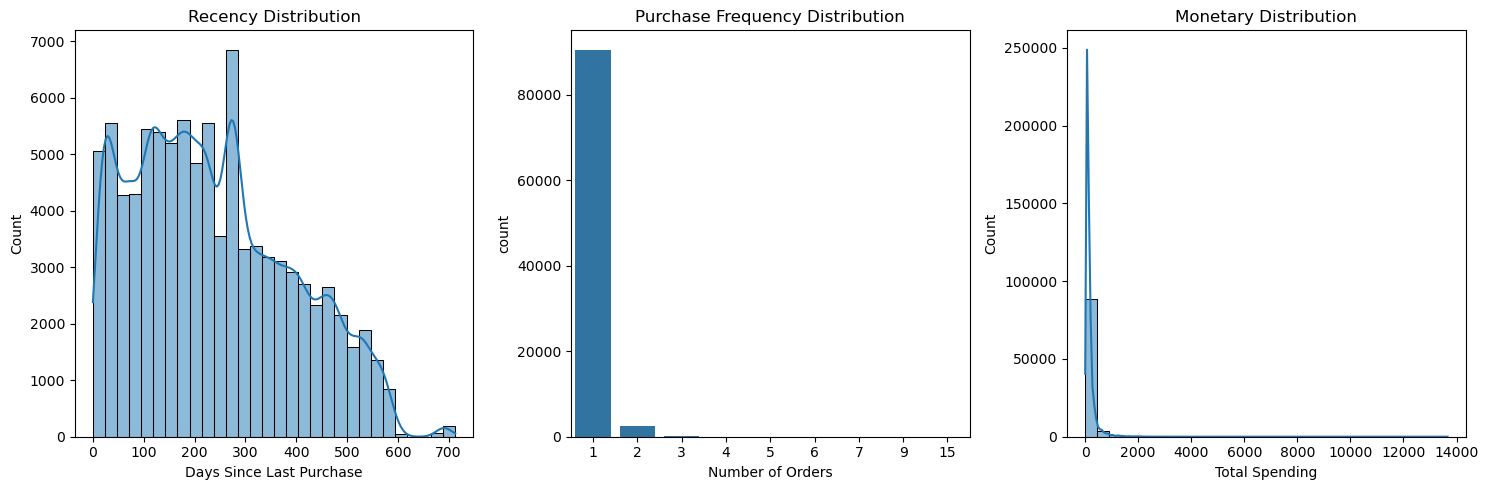

In [45]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.histplot(rfm["Recency"], bins=30, kde=True)
plt.title("Recency Distribution")
plt.xlabel("Days Since Last Purchase")

plt.subplot(1, 3, 2)
sns.countplot(data=rfm, x="Frequency")
plt.title("Purchase Frequency Distribution")
plt.xlabel("Number of Orders")

plt.subplot(1, 3, 3)
sns.histplot(rfm["Monetary"], bins=30, kde=True)
plt.title("Monetary Distribution")
plt.xlabel("Total Spending")

plt.tight_layout()
plt.show()

### Step 6 – RFM Score Calculation

In [46]:
# Recency Score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
)

# Frequency Score
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

# Monetary Score
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,3
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,3,1,1
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4


### Step 7 – Calculate Overall RFM Score

In [47]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int) +
    rfm["F_Score"].astype(int) +
    rfm["M_Score"].astype(int)
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,3,8
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,3,1,1,5
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2,4
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1,4
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4,7


### Step 8 – Customer Segmentation

In [48]:
def segment_customer(row):

    if row["RFM_Score"] >= 10:
        return "Best Customers"

    elif row["RFM_Score"] >= 8:
        return "Loyal Customers"

    elif row["RFM_Score"] >= 6:
        return "Potential Customers"

    elif row["RFM_Score"] >= 4:
        return "At Risk"

    else:
        return "Lost Customers"


rfm["Customer_Segment"] = rfm.apply(
    segment_customer, axis=1
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,3,8,Loyal Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,3,1,1,5,At Risk
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2,4,At Risk
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1,4,At Risk
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4,7,Potential Customers


### Step 9 – Customer Segment Distribution

In [49]:
segment_counts = rfm["Customer_Segment"].value_counts()

print(segment_counts)

Customer_Segment
Potential Customers    31980
Loyal Customers        31103
Best Customers         15197
At Risk                13559
Lost Customers          1519
Name: count, dtype: int64


### Step 10 – Customer Segmentation Visualization

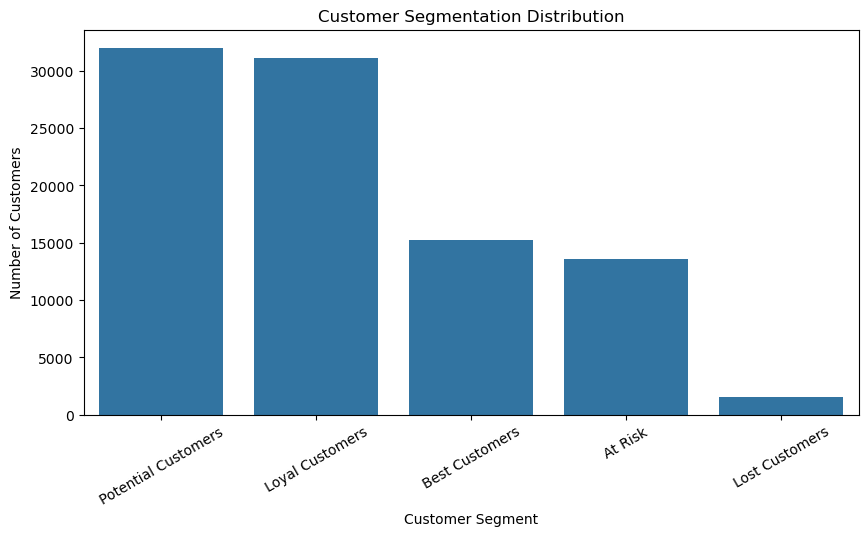

In [50]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=rfm,
    x="Customer_Segment",
    order=rfm["Customer_Segment"].value_counts().index
)

plt.title("Customer Segmentation Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

plt.show()

### Step 11 – Customer Segment Analysis

In [51]:
segment_analysis = rfm.groupby("Customer_Segment").agg(
    Total_Customers=("customer_unique_id", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Average_RFM_Score=("RFM_Score", "mean")
).round(2)

segment_analysis

,Total_Customers,Average_Recency,Average_Frequency,Average_Monetary,Average_RFM_Score
Customer_Segment,,,,,
At Risk,13559,362.13,1.00,67.24,4.66
Best Customers,15197,113.71,1.14,292.23,10.53
Lost Customers,1519,454.07,1.00,43.89,3.00
Loyal Customers,31103,194.38,1.03,193.14,8.46
Potential Customers,31980,273.51,1.00,124.95,6.55


### Step 12 – Customer Segment Percentage

In [52]:
segment_percentage = (
    rfm["Customer_Segment"]
    .value_counts(normalize=True) * 100
).round(2)

print(segment_percentage)

Customer_Segment
Potential Customers    34.26
Loyal Customers        33.32
Best Customers         16.28
At Risk                14.52
Lost Customers          1.63
Name: proportion, dtype: float64


### Step 13 – Average Spending by Customer Segment

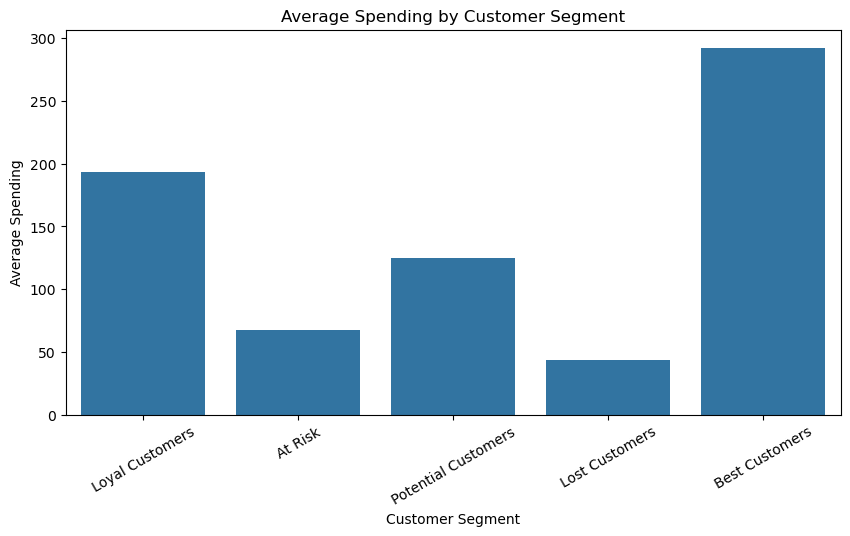

In [53]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=rfm,
    x="Customer_Segment",
    y="Monetary",
    estimator="mean",
    errorbar=None
)

plt.title("Average Spending by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending")
plt.xticks(rotation=30)

plt.show()

### Step 14 – Purchase Frequency by Customer Segment

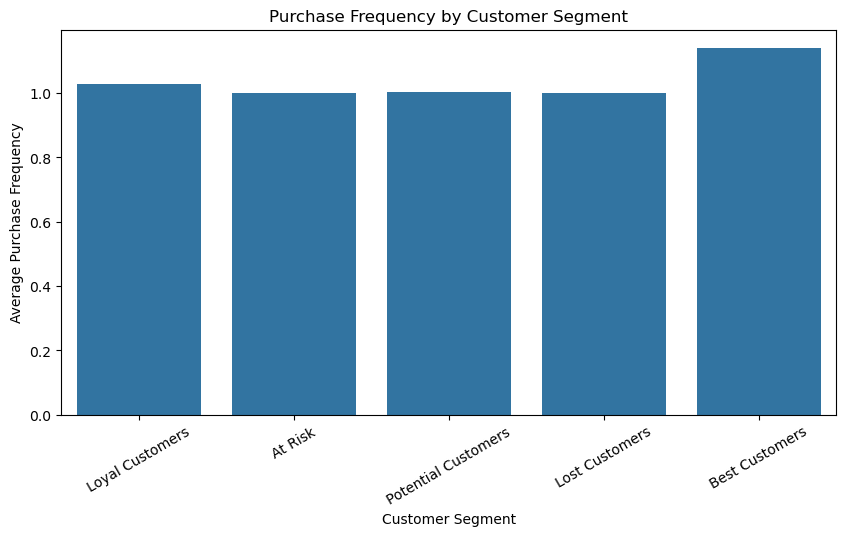

In [54]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=rfm,
    x="Customer_Segment",
    y="Frequency",
    estimator="mean",
    errorbar=None
)

plt.title("Purchase Frequency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Purchase Frequency")
plt.xticks(rotation=30)

plt.show()

### Step 15 – Recency by Customer Segment

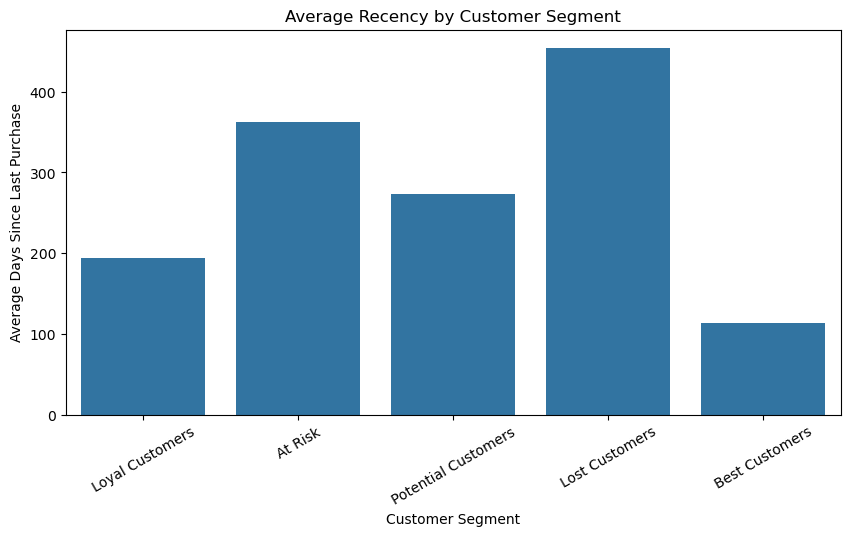

In [55]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=rfm,
    x="Customer_Segment",
    y="Recency",
    estimator="mean",
    errorbar=None
)

plt.title("Average Recency by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Days Since Last Purchase")
plt.xticks(rotation=30)

plt.show()

### Step 16 – Customer Spending vs Recency

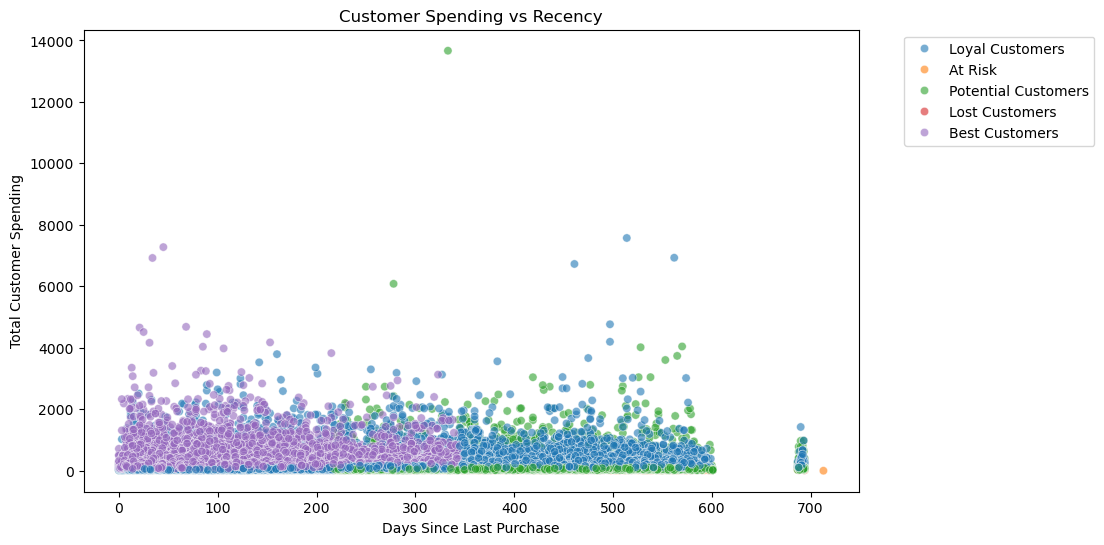

In [56]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Customer_Segment",
    alpha=0.6
)

plt.title("Customer Spending vs Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Total Customer Spending")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")

plt.show()

### Step 17 – Final EDA Business Insights

In [57]:
print("CUSTOMER ANALYSIS SUMMARY")

print("\nTotal Customers:", rfm["customer_unique_id"].nunique())

print("\nCustomer Segments:")
print(rfm["Customer_Segment"].value_counts())

print("\nAverage Customer Spending:",
      round(rfm["Monetary"].mean(), 2))

print("\nAverage Purchase Frequency:",
      round(rfm["Frequency"].mean(), 2))

print("\nAverage Recency:",
      round(rfm["Recency"].mean(), 2))

print("\nHighest Spending Segment:",
      segment_analysis["Average_Monetary"].idxmax())

print("\nHighest Customer Segment:",
      segment_analysis["Total_Customers"].idxmax())

CUSTOMER ANALYSIS SUMMARY

Total Customers: 93358

Customer Segments:
Customer_Segment
Potential Customers    31980
Loyal Customers        31103
Best Customers         15197
At Risk                13559
Lost Customers          1519
Name: count, dtype: int64

Average Customer Spending: 165.2

Average Purchase Frequency: 1.03

Average Recency: 236.94

Highest Spending Segment: Best Customers

Highest Customer Segment: Potential Customers


### Step 18 – Data Quality and Final Checks

In [58]:
print("Dataset Shape:", rfm.shape)

print("\nMissing Values:")
print(rfm.isnull().sum())

print("\nDuplicate Rows:", rfm.duplicated().sum())

print("\nDuplicate Customer IDs:",
      rfm["customer_unique_id"].duplicated().sum())

print("\nNegative Monetary Values:",
      (rfm["Monetary"] < 0).sum())

print("\nNegative Recency Values:",
      (rfm["Recency"] < 0).sum())

print("\nNegative Frequency Values:",
      (rfm["Frequency"] < 0).sum())

Dataset Shape: (93358, 9)

Missing Values:
customer_unique_id    0
Recency               0
Frequency             0
Monetary              0
R_Score               0
F_Score               0
M_Score               0
RFM_Score             0
Customer_Segment      0
dtype: int64

Duplicate Rows: 0

Duplicate Customer IDs: 0

Negative Monetary Values: 0

Negative Recency Values: 0

Negative Frequency Values: 0


### Step 19 – Export Final EDA Dataset

In [59]:
rfm.to_csv(
    "customer_rfm_eda.csv",
    index=False
)

print("Final EDA dataset saved successfully!")

Final EDA dataset saved successfully!
